<a href="https://colab.research.google.com/github/SenudaR20/visual-anomaly-detection/blob/main/algorithms/VAE/VAE_hazelnut.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Import Libraries

In [2]:
# Algorithm 2: Variational Autoencoder (VAE)
# Dataset: Hazelnut (MVTec AD)

import os
import random
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from PIL import Image

from sklearn.model_selection import train_test_split
from tensorflow.keras import layers, Model
from sklearn.metrics import confusion_matrix, classification_report

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)


In [3]:
# connecting google Drive

from google .colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
DATA_ROOT = Path(
    "/content/drive/MyDrive/MvTech_Dataset/hazelnut"
)

TRAIN_DIR = DATA_ROOT / "train" / "good"
TEST_DIR = DATA_ROOT / "test"
MASK_DIR = DATA_ROOT / "ground_truth"

assert TRAIN_DIR.exists(), (
    f"Training folder not found: {TRAIN_DIR}"
)

assert TEST_DIR.exists(), (
    f"Test folder not found: {TEST_DIR}"
)

print("Dataset found:", DATA_ROOT)
print("Normal training folder:", TRAIN_DIR)
print("Test folder:", TEST_DIR)


Dataset found: /content/drive/MyDrive/MvTech_Dataset/hazelnut
Normal training folder: /content/drive/MyDrive/MvTech_Dataset/hazelnut/train/good
Test folder: /content/drive/MyDrive/MvTech_Dataset/hazelnut/test


In [5]:

IMAGE_EXTENSIONS = {".png", ".jpg", ".jpeg", ".bmp"}

def get_images(folder):
    folder = Path(folder)

    if not folder.exists():
        return []

    return sorted([
        path
        for path in folder.rglob("*")
        if path.is_file()
        and path.suffix.lower() in IMAGE_EXTENSIONS
    ])


# Normal images for training
train_images = get_images(TRAIN_DIR)

# All test images, including normal and defective examples
test_images = []

for folder in sorted(TEST_DIR.iterdir()):
    if folder.is_dir():
        test_images.extend(get_images(folder))

print("Normal training images:", len(train_images))
print("Total test images:", len(test_images))

print("\nTest categories:")
for folder in sorted(TEST_DIR.iterdir()):
    if folder.is_dir():
        print(f"{folder.name}: {len(get_images(folder))}")


Normal training images: 391
Total test images: 110

Test categories:
crack: 18
cut: 17
good: 40
hole: 18
print: 17


Preprocess the images

In [6]:

IMG_HEIGHT = 128
IMG_WIDTH = 128
CHANNELS = 3

def preprocess_image(image_path):
    image = Image.open(image_path).convert("RGB")

    image = image.resize(
        (IMG_WIDTH, IMG_HEIGHT),
        Image.Resampling.BILINEAR
    )

    return np.asarray(
        image,
        dtype=np.float32
    ) / 255.0


X_train = np.stack([
    preprocess_image(path)
    for path in train_images
])

print("Training array shape:", X_train.shape)
print("Minimum pixel value:", X_train.min())
print("Maximum pixel value:", X_train.max())


Training array shape: (391, 128, 128, 3)
Minimum pixel value: 0.07058824
Maximum pixel value: 1.0


Split the normal images into training and validation sets

In [7]:

X_train_final, X_val = train_test_split(
    X_train,
    test_size=0.15,
    random_state=SEED,
    shuffle=True
)

print("Training images:", X_train_final.shape)
print("Validation images:", X_val.shape)


Training images: (332, 128, 128, 3)
Validation images: (59, 128, 128, 3)


Build the VAE encoder

In [8]:
LATENT_DIM = 32

# Encoder

encoder_inputs = layers.Input(shape=(IMG_HEIGHT, IMG_WIDTH, CHANNELS), name="encoder_input") # Input layer

# First encoder block
x = layers.Conv2D(32,3, strides=2, activation="relu", padding="same")(encoder_inputs)
x = layers.BatchNormalization()(x)
x = layers.ReLU()(x)

# Second encoder block
x = layers.Conv2D(64,3, strides=2, activation="relu", padding="same")(x)
x = layers.BatchNormalization()(x)
x = layers.ReLU()(x)

# Third encoder block
x = layers.Conv2D(128,3, strides=2, activation="relu", padding="same")(x)
x = layers.BatchNormalization()(x)
x = layers.ReLU()(x)

# Fourth encoder block
x = layers.Conv2D(128,3, strides=2, activation="relu", padding="same")(x)
x = layers.BatchNormalization()(x)
x = layers.ReLU()(x)

x = layers.Flatten()(x)
x = layers.Dense(256, activation="relu")(x)

z_mean = layers.Dense(LATENT_DIM, name="z_mean")(x)
z_log_var = layers.Dense(LATENT_DIM, name="z_log_var")(x)

encoder = Model(encoder_inputs, [z_mean, z_log_var], name = "VAE_encoder")
encoder.summary()




Model: "VAE_encoder"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ encoder_input       │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 64, 64,    │        896 │ encoder_input[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 64, 64,    │        128 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu (ReLU)        │ (None, 64, 64,    │          0 │ batch_normalizat… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 32, 32,    │     18,496 │ re_lu[0][0]       │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │        256 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_1 (ReLU)      │ (None, 32, 32,    │          0 │ batch_normalizat… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 16, 16,    │     73,856 │ re_lu_1[0][0]     │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 16, 16,    │        512 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_2 (ReLU)      │ (None, 16, 16,    │          0 │ batch_normalizat… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 8, 8, 128) │    147,584 │ re_lu_2[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 8, 8, 128) │        512 │ conv2d_3[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_3 (ReLU)      │ (None, 8, 8, 128) │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten (Flatten)   │ (None, 8192)      │          0 │ re_lu_3[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 256)       │  2,097,408 │ flatten[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_mean (Dense)      │ (None, 32)        │      8,224 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_log_var (Dense)   │ (None, 32)        │      8,224 │ dense[0][0]       │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 2,356,096 (8.99 MB)

 Trainable params: 2,355,392 (8.99 MB)

 Non-trainable params: 704 (2.75 KB)

Implement the reparameterization trick

In [9]:
class Sampling(layers.Layer):
  """Sampling a latent vector using the reparameterization trick."""

  def call(self, inputs):
        z_mean, z_log_var = inputs

        epsilon = tf.random.normal(shape=tf.shape(z_mean))

        z = z_mean + tf.exp(0.5 * z_log_var) * epsilon

        return z


sampling = Sampling(name="sampling")
z = sampling([z_mean, z_log_var])

print("Latent mean shape:", z_mean.shape)
print("Latent log-variance shape:", z_log_var.shape)
print("Sampled latent shape:", z.shape)


Latent mean shape: (None, 32)
Latent log-variance shape: (None, 32)
Sampled latent shape: (None, 32)


Build the VAE decoder

In [10]:
decoder_inputs = layers.Input(shape=(LATENT_DIM,), name="decoder_input") #Input Layer

x = layers.Dense(8*8*128, activation="relu")(decoder_inputs)
x = layers.Reshape((8,8,128))(x)


x = layers.Conv2DTranspose(128,3, strides=2, activation="relu", padding="same")(x)
x = layers.BatchNormalization()(x)
x = layers.ReLU()(x)

x = layers.Conv2DTranspose(128,3, strides=2, activation="relu", padding="same")(x)
x = layers.BatchNormalization()(x)
x = layers.ReLU()(x)

x = layers.Conv2DTranspose(64,3, strides=2, activation="relu", padding="same")(x)
x = layers.BatchNormalization()(x)
x = layers.ReLU()(x)

x = layers.Conv2DTranspose(32,3, strides=2, activation="relu", padding="same")(x)
x = layers.BatchNormalization()(x)
x = layers.ReLU()(x)

decoder_outputs = layers.Conv2D(CHANNELS, kernel_size=3, padding="same", activation="sigmoid", name="reconstructed_image")(x)

decoder = Model(decoder_inputs, decoder_outputs, name="VAE_decoder")
decoder.summary()

Model: "VAE_decoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ decoder_input (InputLayer)      │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8192)           │       270,336 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 16, 16, 128)    │       147,584 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_4 (ReLU)                  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, 32, 32, 128)    │       147,584 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_5 (ReLU)                  │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_2              │ (None, 64, 64, 64)     │        73,792 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_6 (ReLU)                  │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_3              │ (None, 128, 128, 32)   │        18,464 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_7 (ReLU)                  │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reconstructed_image (Conv2D)    │ (None, 128, 128, 3)    │           867 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 660,035 (2.52 MB)

 Trainable params: 659,331 (2.52 MB)

 Non-trainable params: 704 (2.75 KB)

Combine the encoder and decoder

In [11]:

# Connect the full VAE
vae_outputs = decoder(z)

vae = Model(
    encoder_inputs,
    vae_outputs,
    name="Hazelnut_VAE"
)

print("VAE constructed successfully.")
print("Input shape:", vae.input_shape)
print("Output shape:", vae.output_shape)


VAE constructed successfully.
Input shape: (None, 128, 128, 3)
Output shape: (None, 128, 128, 3)


Implement the VAE loss function


In [12]:

def vae_loss_function(original_images, reconstructed_images):
    # Reconstruction loss, summed across pixels and RGB channels
    reconstruction_loss = tf.reduce_sum(
        tf.square(original_images - reconstructed_images),
        axis=[1, 2, 3]
    )

    # KL divergence between learned latent distribution and N(0, I)
    kl_loss = -0.5 * tf.reduce_sum(
        1.0
        + z_log_var
        - tf.square(z_mean)
        - tf.exp(z_log_var),
        axis=1
    )

    total_loss = tf.reduce_mean(
        reconstruction_loss + kl_loss
    )

    return (
        total_loss,
        tf.reduce_mean(reconstruction_loss),
        tf.reduce_mean(kl_loss)
    )


Set up the training datasets


In [16]:
BATCH_SIZE = 16

train_ds = (
    tf.data.Dataset
    .from_tensor_slices(X_train_final)
    .shuffle(
        len(X_train_final),
        seed=SEED
    )
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

val_ds = (
    tf.data.Dataset
    .from_tensor_slices(X_val)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

print("Training batches:",
      tf.data.experimental.cardinality(train_ds).numpy())

print("Validation batches:",
      tf.data.experimental.cardinality(val_ds).numpy())

Training batches: 21
Validation batches: 4


Configure the optimizer and training metrics

In [17]:

LEARNING_RATE = 0.001

optimizer = tf.keras.optimizers.Adam(
    learning_rate=LEARNING_RATE
)

train_loss_metric = tf.keras.metrics.Mean(name="train_loss")
train_reconstruction_metric = tf.keras.metrics.Mean(name="train_reconstruction_loss")
train_kl_metric = tf.keras.metrics.Mean(name="train_kl_loss")

val_loss_metric = tf.keras.metrics.Mean(name="val_loss")
val_reconstruction_metric = tf.keras.metrics.Mean(name="val_reconstruction_loss")
val_kl_metric = tf.keras.metrics.Mean(name="val_kl_loss")

print("Optimizer and metrics configured.")


Optimizer and metrics configured.


Create the custom training loop

In [18]:

@tf.function
def train_step(images):
    with tf.GradientTape() as tape:
        # Encode the images
        mean, log_var = encoder(images, training=True)

        # Sample latent vectors
        sampled_z = sampling([mean, log_var])

        # Reconstruct the images
        reconstructed = decoder(sampled_z, training=True)

        # Reconstruction loss
        reconstruction_loss = tf.reduce_sum(
            tf.square(images - reconstructed),
            axis=[1, 2, 3]
        )

        # KL divergence
        kl_loss = -0.5 * tf.reduce_sum(
            1.0
            + log_var
            - tf.square(mean)
            - tf.exp(log_var),
            axis=1
        )

        total_loss = tf.reduce_mean(
            reconstruction_loss + kl_loss
        )

    trainable_variables = (
        encoder.trainable_variables
        + decoder.trainable_variables
    )

    gradients = tape.gradient(
        total_loss,
        trainable_variables
    )

    optimizer.apply_gradients(
        zip(gradients, trainable_variables)
    )

    return (
        total_loss,
        tf.reduce_mean(reconstruction_loss),
        tf.reduce_mean(kl_loss)
    )


@tf.function
def validation_step(images):
    mean, log_var = encoder(images, training=False)

    # Use the mean for deterministic validation reconstruction
    reconstructed = decoder(mean, training=False)

    reconstruction_loss = tf.reduce_sum(
        tf.square(images - reconstructed),
        axis=[1, 2, 3]
    )

    kl_loss = -0.5 * tf.reduce_sum(
        1.0
        + log_var
        - tf.square(mean)
        - tf.exp(log_var),
        axis=1
    )

    total_loss = tf.reduce_mean(
        reconstruction_loss + kl_loss
    )

    return (
        total_loss,
        tf.reduce_mean(reconstruction_loss),
        tf.reduce_mean(kl_loss)
    )


print("Training and validation steps defined.")


Training and validation steps defined.


Run one test batch before full training

In [19]:

for batch in train_ds.take(1):
    total, reconstruction, kl = train_step(batch)

    print("Total loss:", float(total))
    print("Reconstruction loss:", float(reconstruction))
    print("KL-divergence loss:", float(kl))


Total loss: 7128.5693359375
Reconstruction loss: 7084.0595703125
KL-divergence loss: 44.50946807861328


Setup model saving and training history

In [13]:

OUTPUT_DIR = Path(
    "/content/drive/MyDrive/VAE_Hazelnut_Results"
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

EPOCHS = 50
PATIENCE = 8

history = {
    "train_loss": [],
    "train_reconstruction_loss": [],
    "train_kl_loss": [],
    "val_loss": [],
    "val_reconstruction_loss": [],
    "val_kl_loss": []
}

best_val_loss = float("inf")
best_epoch = 0
epochs_without_improvement = 0

print("Results directory:", OUTPUT_DIR)
print("Maximum epochs:", EPOCHS)


Results directory: /content/drive/MyDrive/VAE_Hazelnut_Results
Maximum epochs: 50


Train the VAE

In [21]:

for epoch in range(EPOCHS):
    # Reset metrics for this epoch
    train_loss_metric.reset_state()
    train_reconstruction_metric.reset_state()
    train_kl_metric.reset_state()

    val_loss_metric.reset_state()
    val_reconstruction_metric.reset_state()
    val_kl_metric.reset_state()

    # Training
    for batch in train_ds:
        total, reconstruction, kl = train_step(batch)

        train_loss_metric.update_state(total)
        train_reconstruction_metric.update_state(reconstruction)
        train_kl_metric.update_state(kl)

    # Validation
    for batch in val_ds:
        total, reconstruction, kl = validation_step(batch)

        val_loss_metric.update_state(total)
        val_reconstruction_metric.update_state(reconstruction)
        val_kl_metric.update_state(kl)

    # Store epoch averages
    train_loss = float(train_loss_metric.result())
    train_recon = float(train_reconstruction_metric.result())
    train_kl = float(train_kl_metric.result())

    val_loss = float(val_loss_metric.result())
    val_recon = float(val_reconstruction_metric.result())
    val_kl = float(val_kl_metric.result())

    history["train_loss"].append(train_loss)
    history["train_reconstruction_loss"].append(train_recon)
    history["train_kl_loss"].append(train_kl)
    history["val_loss"].append(val_loss)
    history["val_reconstruction_loss"].append(val_recon)
    history["val_kl_loss"].append(val_kl)

    print(
        f"Epoch {epoch + 1:02d}/{EPOCHS} | "
        f"Train: {train_loss:.2f} "
        f"(Recon {train_recon:.2f}, KL {train_kl:.2f}) | "
        f"Val: {val_loss:.2f} "
        f"(Recon {val_recon:.2f}, KL {val_kl:.2f})"
    )

    # Save the best encoder and decoder together
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_epoch = epoch + 1
        epochs_without_improvement = 0

        vae.save_weights(
            str(OUTPUT_DIR / "best_vae.weights.h5")
        )

    else:
        epochs_without_improvement += 1

    # Early stopping
    if epochs_without_improvement >= PATIENCE:
        print(
            f"\nEarly stopping at epoch {epoch + 1}. "
            f"Best epoch: {best_epoch}"
        )
        break

print("\nTraining finished.")
print("Best epoch:", best_epoch)
print("Best validation loss:", round(best_val_loss, 4))


Epoch 01/50 | Train: 143213.38 (Recon 2206.71, KL 141006.67) | Val: 4730.90 (Recon 4730.89, KL 0.00)
Epoch 02/50 | Train: 477.82 (Recon 384.60, KL 93.22) | Val: 4695.23 (Recon 4695.23, KL 0.00)
Epoch 03/50 | Train: 251.88 (Recon 189.30, KL 62.58) | Val: 4670.55 (Recon 4670.55, KL 0.00)
Epoch 04/50 | Train: 177.16 (Recon 131.74, KL 45.42) | Val: 4683.40 (Recon 4683.40, KL 0.00)
Epoch 05/50 | Train: 155.07 (Recon 115.50, KL 39.57) | Val: 4674.41 (Recon 4674.41, KL 0.00)
Epoch 06/50 | Train: 141.54 (Recon 104.96, KL 36.59) | Val: 4665.71 (Recon 4665.71, KL 0.00)
Epoch 07/50 | Train: 132.41 (Recon 98.06, KL 34.35) | Val: 4655.42 (Recon 4655.42, KL 0.00)
Epoch 08/50 | Train: 122.28 (Recon 90.75, KL 31.54) | Val: 4630.00 (Recon 4630.00, KL 0.00)
Epoch 09/50 | Train: 115.92 (Recon 86.44, KL 29.48) | Val: 4610.91 (Recon 4610.90, KL 0.01)
Epoch 10/50 | Train: 109.90 (Recon 81.61, KL 28.29) | Val: 4578.45 (Recon 4578.45, KL 0.01)
Epoch 11/50 | Train: 102.54 (Recon 75.43, KL 27.12) | Val: 4548.14

Plot the training and validation loss


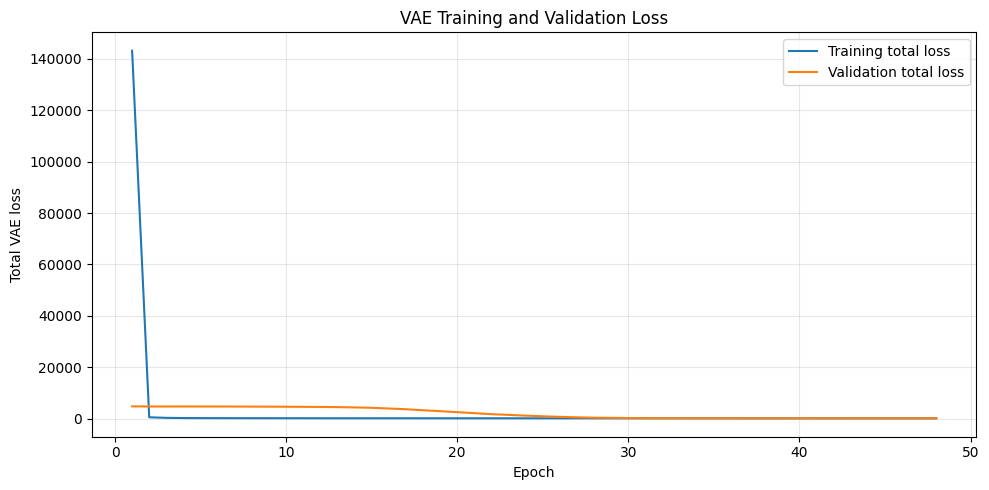

In [22]:

epochs_completed = range(1, len(history["train_loss"]) + 1)

plt.figure(figsize=(10, 5))

plt.plot(
    epochs_completed,
    history["train_loss"],
    label="Training total loss"
)

plt.plot(
    epochs_completed,
    history["val_loss"],
    label="Validation total loss"
)

plt.xlabel("Epoch")
plt.ylabel("Total VAE loss")
plt.title("VAE Training and Validation Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


Examine the two loss components

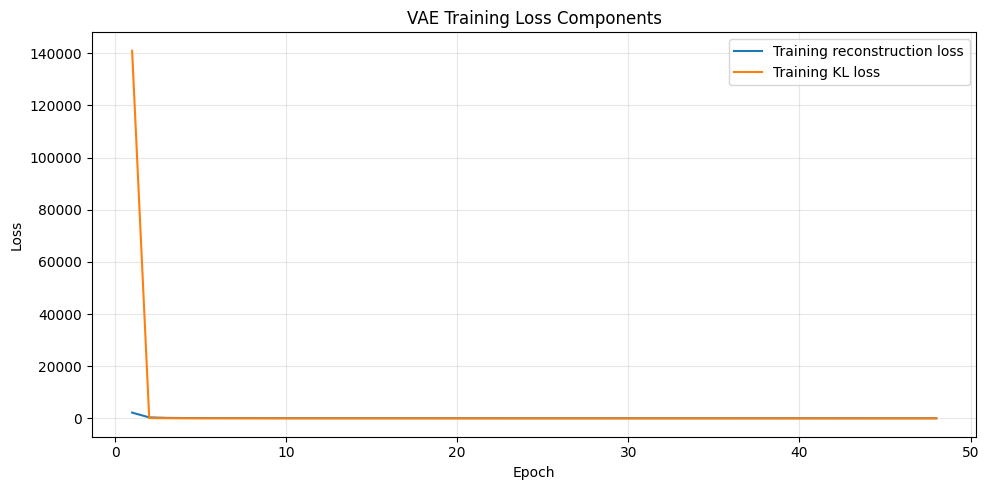

In [23]:

plt.figure(figsize=(10, 5))

plt.plot(
    epochs_completed,
    history["train_reconstruction_loss"],
    label="Training reconstruction loss"
)

plt.plot(
    epochs_completed,
    history["train_kl_loss"],
    label="Training KL loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("VAE Training Loss Components")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


Restore the best checkpoint

In [14]:

# Restore the best encoder and decoder weights
vae.load_weights(
    str(OUTPUT_DIR / "best_vae.weights.h5")
)

print("Best VAE checkpoint loaded.")
print("Best epoch:", best_epoch)
print("Best validation loss:", best_val_loss)


Best VAE checkpoint loaded.
Best epoch: 0
Best validation loss: inf


Visualize VAE reconstructions

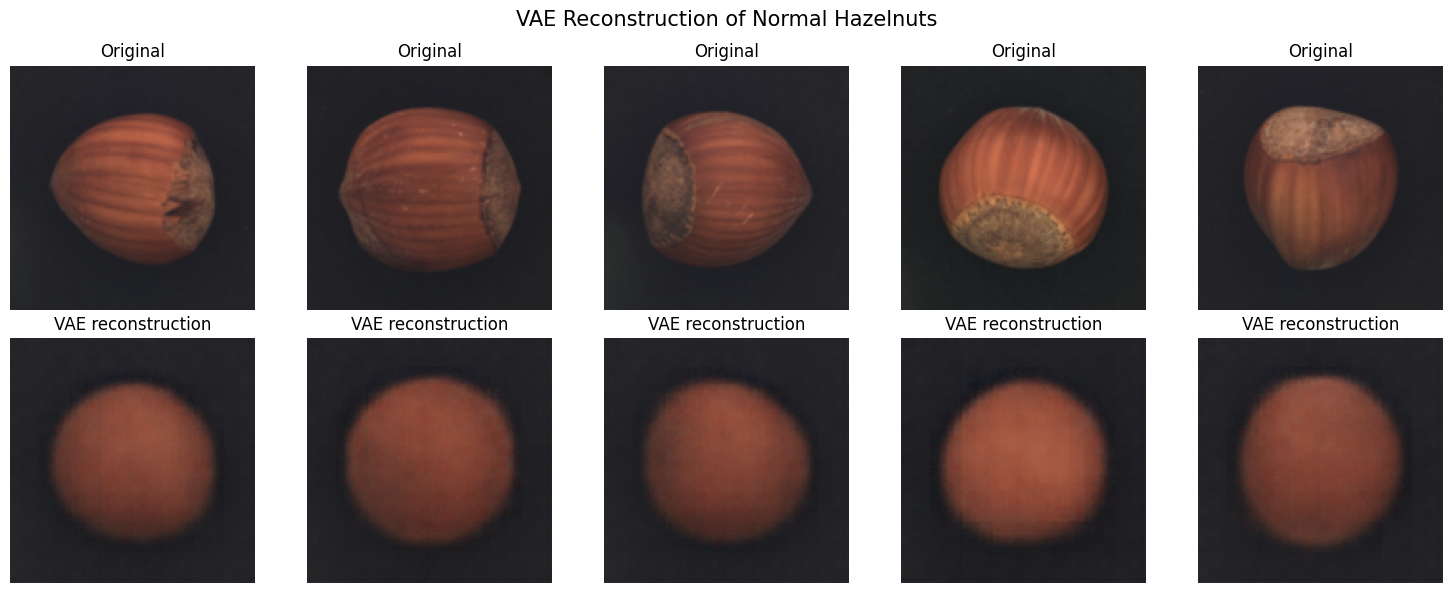

Mean absolute reconstruction error: 0.01970634050667286
Mean latent variance: 0.545384407043457


In [25]:

n = min(5, len(X_val))
sample_images = X_val[:n]

# Obtain latent means and decode them
sample_means, sample_log_vars = encoder.predict(
    sample_images,
    verbose=0
)

reconstructed_images = decoder.predict(
    sample_means,
    verbose=0
)

plt.figure(figsize=(15, 6))

for i in range(n):
    plt.subplot(2, n, i + 1)
    plt.imshow(sample_images[i])
    plt.title("Original")
    plt.axis("off")

    plt.subplot(2, n, n + i + 1)
    plt.imshow(np.clip(reconstructed_images[i], 0, 1))
    plt.title("VAE reconstruction")
    plt.axis("off")

plt.suptitle("VAE Reconstruction of Normal Hazelnuts", fontsize=15)
plt.tight_layout()
plt.show()

print("Mean absolute reconstruction error:",
      float(np.mean(np.abs(sample_images - reconstructed_images))))

print("Mean latent variance:",
      float(np.mean(np.exp(sample_log_vars))))


Plot the loss curves on a logarithmic scale

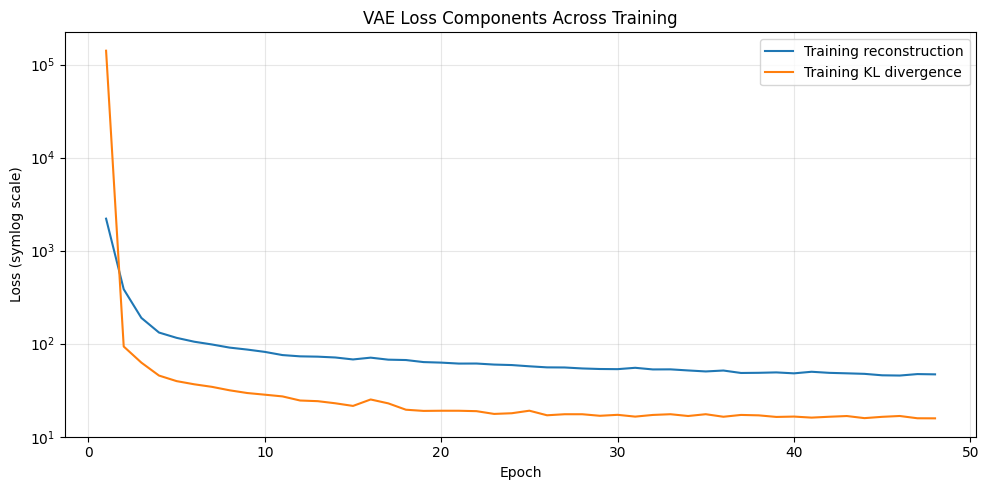

In [26]:

plt.figure(figsize=(10, 5))

plt.plot(
    epochs_completed,
    history["train_reconstruction_loss"],
    label="Training reconstruction"
)

plt.plot(
    epochs_completed,
    history["train_kl_loss"],
    label="Training KL divergence"
)

plt.yscale("symlog", linthresh=1)
plt.xlabel("Epoch")
plt.ylabel("Loss (symlog scale)")
plt.title("VAE Loss Components Across Training")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


Load the test images

In [18]:

# Label normal images as 0 and defective images as 1
test_labels = np.array([
    0 if path.parent.name == "good" else 1
    for path in test_images
])

test_categories = np.array([
    path.parent.name for path in test_images
])

# Preprocess all test images
X_test = np.stack([
    preprocess_image(path)
    for path in test_images
])

print("Test array shape:", X_test.shape)
print("Normal images:", int(np.sum(test_labels == 0)))
print("Defective images:", int(np.sum(test_labels == 1)))


Test array shape: (110, 128, 128, 3)
Normal images: 40
Defective images: 70


Calculate VAE anomaly scores

In [19]:

# Encode test images
test_means, test_log_vars = encoder.predict(
    X_test,
    batch_size=16,
    verbose=1
)

# Reconstruct using the latent means
X_reconstructed = decoder.predict(
    test_means,
    batch_size=16,
    verbose=1
)

# Pixel-level mean absolute reconstruction errors
test_error_maps = np.mean(
    np.abs(X_test - X_reconstructed),
    axis=-1
)

# One anomaly score per image
image_anomaly_scores = np.mean(
    test_error_maps,
    axis=(1, 2)
)

print("Mean normal score:",
      float(image_anomaly_scores[test_labels == 0].mean()))

print("Mean defective score:",
      float(image_anomaly_scores[test_labels == 1].mean()))


7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 135ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 2s 245ms/step
Mean normal score: 0.022744009271264076
Mean defective score: 0.027560101822018623


Evaluate image-level ROC-AUC

VAE image-level ROC-AUC: 0.6104


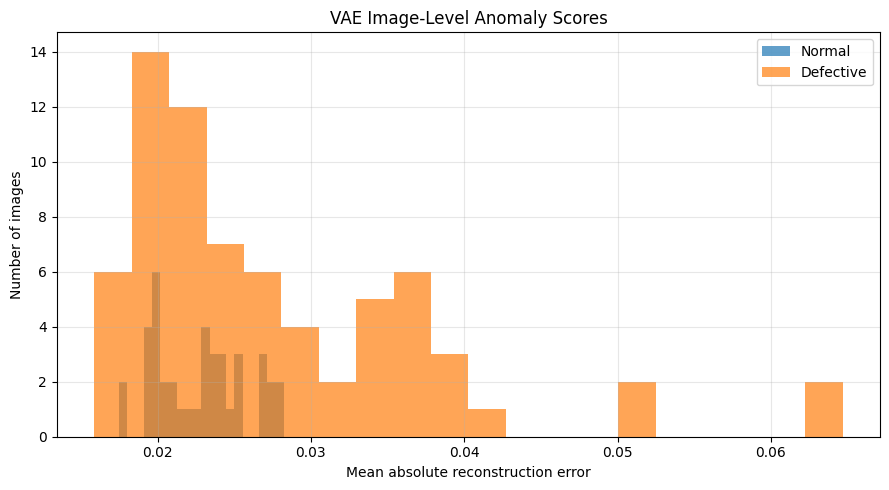

In [29]:

from sklearn.metrics import roc_auc_score

if len(np.unique(test_labels)) == 2:
    image_roc_auc = roc_auc_score(
        test_labels,
        image_anomaly_scores
    )
    print(f"VAE image-level ROC-AUC: {image_roc_auc:.4f}")
else:
    print("ROC-AUC requires both normal and defective test images.")

plt.figure(figsize=(9, 5))

plt.hist(
    image_anomaly_scores[test_labels == 0],
    bins=20,
    alpha=0.7,
    label="Normal"
)

plt.hist(
    image_anomaly_scores[test_labels == 1],
    bins=20,
    alpha=0.7,
    label="Defective"
)

plt.xlabel("Mean absolute reconstruction error")
plt.ylabel("Number of images")
plt.title("VAE Image-Level Anomaly Scores")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


Select a threshold using normal validation images

In [21]:

# Reconstruct normal validation images using latent means
val_means, val_log_vars = encoder.predict(
    X_val,
    batch_size=16,
    verbose=0
)

val_reconstructions = decoder.predict(
    val_means,
    batch_size=16,
    verbose=0
)

# Calculate image-level validation scores
val_error_maps = np.mean(
    np.abs(X_val - val_reconstructions),
    axis=-1
)

val_anomaly_scores = np.mean(
    val_error_maps,
    axis=(1, 2)
)

# Threshold based on the 95th percentile of normal validation scores
THRESHOLD_PERCENTILE = 95

anomaly_threshold = np.percentile(
    val_anomaly_scores,
    THRESHOLD_PERCENTILE
)

print("VAE anomaly threshold:", round(float(anomaly_threshold), 6))


VAE anomaly threshold: 0.026898


Evaluate classification performance

In [20]:



vae_predictions = (
    image_anomaly_scores > anomaly_threshold
).astype(int)

print("VAE confusion matrix:")
print(confusion_matrix(test_labels, vae_predictions))

print("\nVAE classification report:")
print(classification_report(
    test_labels,
    vae_predictions,
    target_names=["Normal", "Defective"],
    zero_division=0
))


VAE confusion matrix:
[[26 14]
 [34 36]]

VAE classification report:
              precision    recall  f1-score   support

      Normal       0.43      0.65      0.52        40
   Defective       0.72      0.51      0.60        70

    accuracy                           0.56       110
   macro avg       0.58      0.58      0.56       110
weighted avg       0.62      0.56      0.57       110



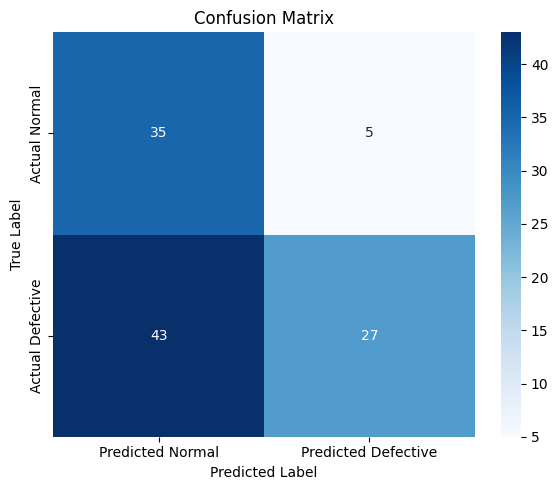

In [33]:
import seaborn as sns
# Compute confusion matrix
cm = confusion_matrix(test_labels, vae_predictions)

# Plot
plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Predicted Normal", "Predicted Defective"],
    yticklabels=["Actual Normal", "Actual Defective"]
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.show()

Save Results

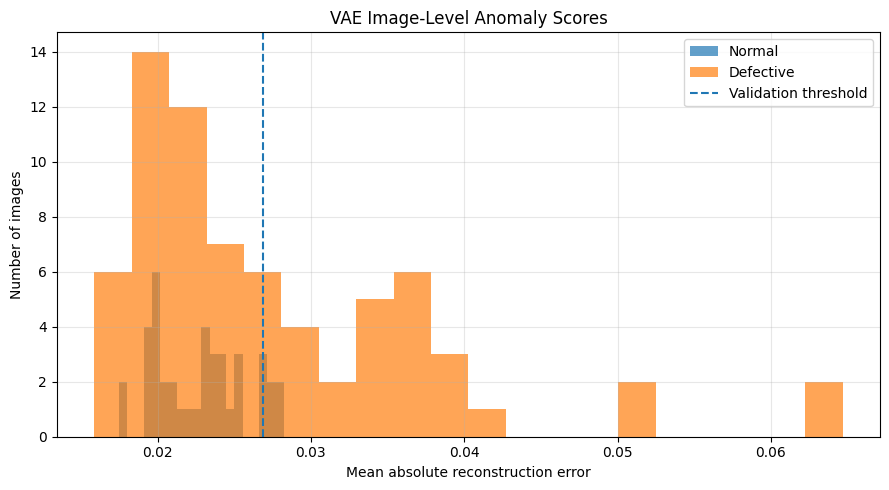

VAE results saved successfully to:
/content/drive/MyDrive/VAE_Hazelnut_Results

Saved files:
- best_vae.weights.h5
- vae_anomaly_score_histogram.png
- vae_classification_report.csv
- vae_confusion_matrix.csv
- vae_metrics.json
- vae_test_predictions.csv
- vae_training_history.csv


In [34]:

import json
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# 1. Save image-level predictions and anomaly scores
predictions_df = pd.DataFrame({
    "image_path": [str(p) for p in test_images],
    "category": test_categories,
    "true_label": test_labels,
    "anomaly_score": image_anomaly_scores,
    "predicted_label": vae_predictions
})

predictions_df.to_csv(
    OUTPUT_DIR / "vae_test_predictions.csv",
    index=False
)

# 2. Save confusion matrix
cm = confusion_matrix(test_labels, vae_predictions)

cm_df = pd.DataFrame(
    cm,
    index=["Actual_Normal", "Actual_Defective"],
    columns=["Predicted_Normal", "Predicted_Defective"]
)

cm_df.to_csv(OUTPUT_DIR / "vae_confusion_matrix.csv")

# 3. Save classification report
report = classification_report(
    test_labels,
    vae_predictions,
    target_names=["Normal", "Defective"],
    output_dict=True,
    zero_division=0
)

pd.DataFrame(report).transpose().to_csv(
    OUTPUT_DIR / "vae_classification_report.csv"
)

# 4. Save training history
pd.DataFrame(history).to_csv(
    OUTPUT_DIR / "vae_training_history.csv",
    index_label="epoch"
)

# 5. Save summary metrics and threshold
metrics = {
    "model": "Convolutional Variational Autoencoder",
    "dataset": "MVTec AD Hazelnut",
    "image_height": IMG_HEIGHT,
    "image_width": IMG_WIDTH,
    "channels": CHANNELS,
    "latent_dim": LATENT_DIM,
    "best_epoch": int(best_epoch),
    "best_validation_loss": float(best_val_loss),
    "threshold_percentile": THRESHOLD_PERCENTILE,
    "anomaly_threshold": float(anomaly_threshold),
    "image_level_roc_auc": float(
        roc_auc_score(test_labels, image_anomaly_scores)
    ),
    "test_accuracy": float(
        accuracy_score(test_labels, vae_predictions)
    ),
    "defective_precision": float(
        precision_score(test_labels, vae_predictions, zero_division=0)
    ),
    "defective_recall": float(
        recall_score(test_labels, vae_predictions, zero_division=0)
    ),
    "defective_f1": float(
        f1_score(test_labels, vae_predictions, zero_division=0)
    ),
    "test_image_count": int(len(test_labels))
}

with open(OUTPUT_DIR / "vae_metrics.json", "w") as f:
    json.dump(metrics, f, indent=4)

# 6. Save the anomaly-score histogram
plt.figure(figsize=(9, 5))
plt.hist(
    image_anomaly_scores[test_labels == 0],
    bins=20,
    alpha=0.7,
    label="Normal"
)
plt.hist(
    image_anomaly_scores[test_labels == 1],
    bins=20,
    alpha=0.7,
    label="Defective"
)
plt.axvline(
    anomaly_threshold,
    linestyle="--",
    label="Validation threshold"
)
plt.xlabel("Mean absolute reconstruction error")
plt.ylabel("Number of images")
plt.title("VAE Image-Level Anomaly Scores")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "vae_anomaly_score_histogram.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

print("VAE results saved successfully to:")
print(OUTPUT_DIR)

print("\nSaved files:")
for path in sorted(OUTPUT_DIR.iterdir()):
    if path.is_file():
        print("-", path.name)
